<a href="https://colab.research.google.com/github/TiTKi1/-ML/blob/main/%D0%9B%D0%A05_%D0%9C%D0%B0%D0%BC%D0%B5%D0%B4%D0%BE%D0%B2_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***Був присутній на парі***





Daily Weather Time Series Data - Delhi, India

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:** Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.

1. Завантажити датасет з Kaggle.
2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).
3. Ознайомитися зі структурою датасету (head(), info(), describe()).
4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

In [1]:
!pip install -q kagglehub prophet

In [62]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from prophet import Prophet
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

plt.rcParams["figure.figsize"] = (14, 5)

In [69]:
import kagglehub

dataset_path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
os.listdir(dataset_path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.


['kaggel_weather_2013_to_2024.csv']

In [71]:
csv_path = os.path.join(dataset_path, "kaggel_weather_2013_to_2024.csv")
df = pd.read_csv(csv_path)
df.head()

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [72]:
df["DATE"] = pd.to_datetime(df["DATE"])
df = df.sort_values("DATE")
df = df[["DATE", "temp", "tempmax", "tempmin", "humidity", "precip", "windspeed", "sealevelpressure"]]
df = df.set_index("DATE")
df = df[~df.index.duplicated(keep="first")]
df = df.asfreq("D")
df.head()

,temp,tempmax,tempmin,humidity,precip,windspeed,sealevelpressure
DATE,,,,,,,
2013-04-14,28.7,37.7,23.1,39.7,2.0,22.3,1008.3
2013-04-15,28.6,37.5,21.1,41.7,0.0,17.6,1005.1
2013-04-16,31.7,40.1,21.9,30.7,0.0,27.7,1001.7
2013-04-17,29.9,36.4,21.0,27.4,0.0,22.3,1002.5
2013-04-18,30.6,37.5,21.7,23.7,0.0,12.4,1003.4


In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   temp              3556 non-null   float64
 1   tempmax           3556 non-null   float64
 2   tempmin           3556 non-null   float64
 3   humidity          3556 non-null   float64
 4   precip            3556 non-null   float64
 5   windspeed         3556 non-null   float64
 6   sealevelpressure  3556 non-null   float64
dtypes: float64(7)
memory usage: 265.6 KB


In [74]:
df.isnull().sum()

,0
temp,693
tempmax,693
tempmin,693
humidity,693
precip,693
windspeed,693
sealevelpressure,693


In [75]:
df = df.ffill()
df.isnull().sum()

,0
temp,0
tempmax,0
tempmin,0
humidity,0
precip,0
windspeed,0
sealevelpressure,0


Графік температури

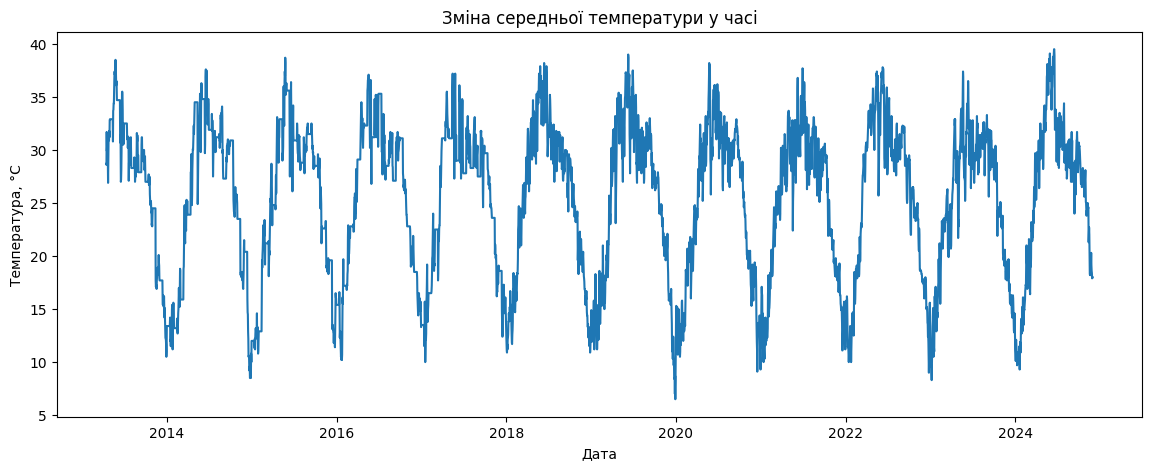

In [76]:
plt.plot(df.index, df["temp"])
plt.title("Зміна середньої температури у часі")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.show()

Ковзне середнє

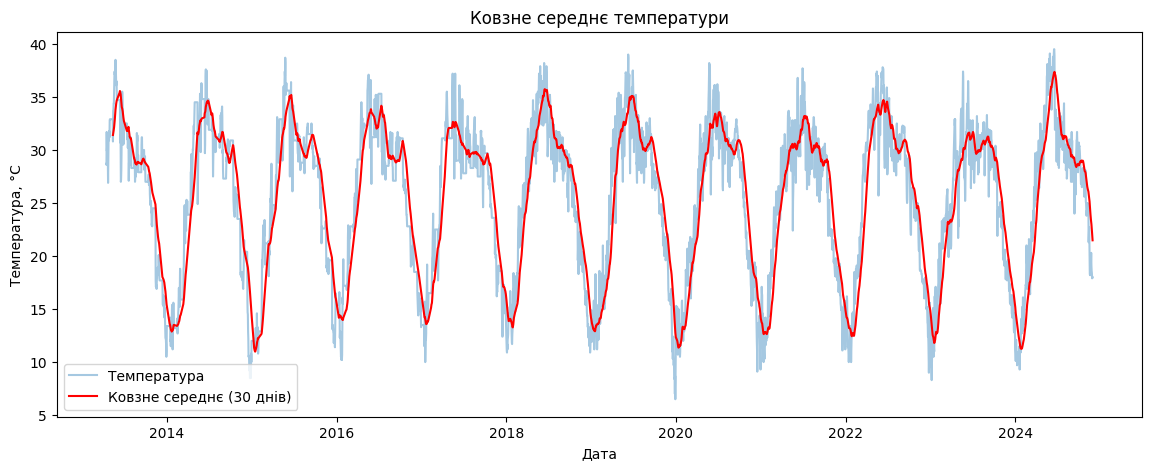

In [77]:
df["temp_rolling_30"] = df["temp"].rolling(window=30).mean()

plt.plot(df.index, df["temp"], alpha=0.4, label="Температура")
plt.plot(df.index, df["temp_rolling_30"], color="red", label="Ковзне середнє (30 днів)")
plt.legend()
plt.title("Ковзне середнє температури")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.show()

Розподіл температури

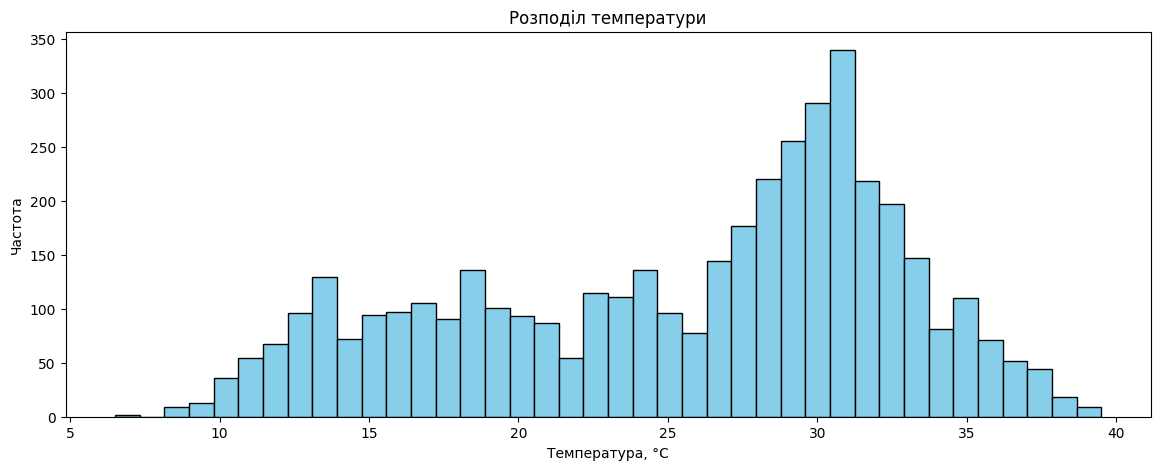

In [78]:
plt.hist(df["temp"], bins=40, color="skyblue", edgecolor="black")
plt.title("Розподіл температури")
plt.xlabel("Температура, °C")
plt.ylabel("Частота")
plt.show()

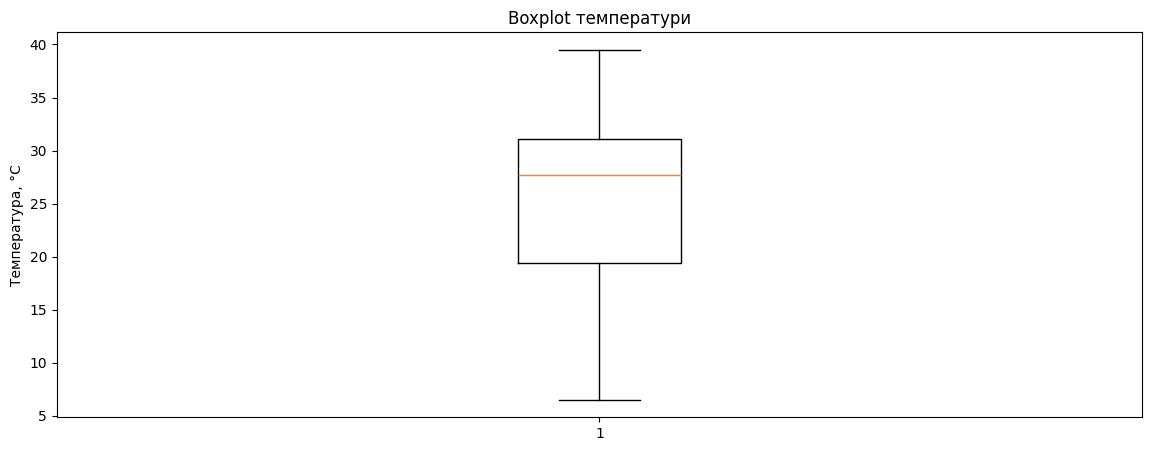

In [79]:
plt.boxplot(df["temp"])
plt.title("Boxplot температури")
plt.ylabel("Температура, °C")
plt.show()

Аналіз автокореляції

ACF

PACF

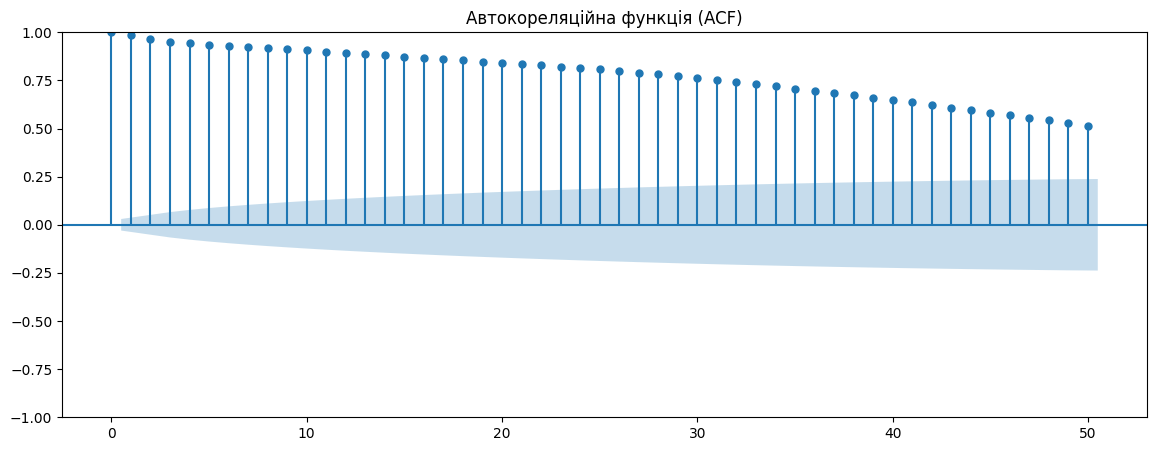

In [80]:
plot_acf(df["temp"], lags=50)
plt.title("Автокореляційна функція (ACF)")
plt.show()

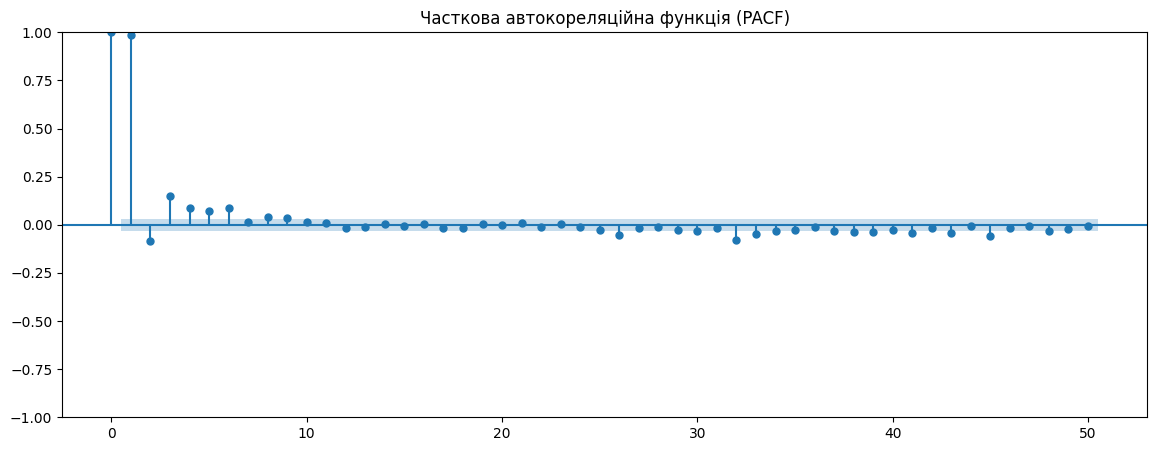

In [81]:
plot_pacf(df["temp"], lags=50)
plt.title("Часткова автокореляційна функція (PACF)")
plt.show()

In [82]:
series = df["temp"]

train_size = int(len(series) * 0.8)
train, test = series.iloc[:train_size], series.iloc[train_size:]

len(train), len(test)

(3399, 850)

In [83]:
train_arima = train.reset_index(drop=True)

arima_model = ARIMA(train_arima, order=(5, 1, 0))
arima_fit = arima_model.fit()
arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast.index = test.index

In [84]:
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -5606.986
Date:                Fri, 09 Oct 2026   AIC                          11225.972
Time:                        09:13:17   BIC                          11262.757
Sample:                             0   HQIC                         11239.120
                               - 3399                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0616      0.014      4.479      0.000       0.035       0.089
ar.L2         -0.1716      0.015    -11.742      0.000      -0.200      -0.143
ar.L3         -0.1061      0.015     -6.979      0.0

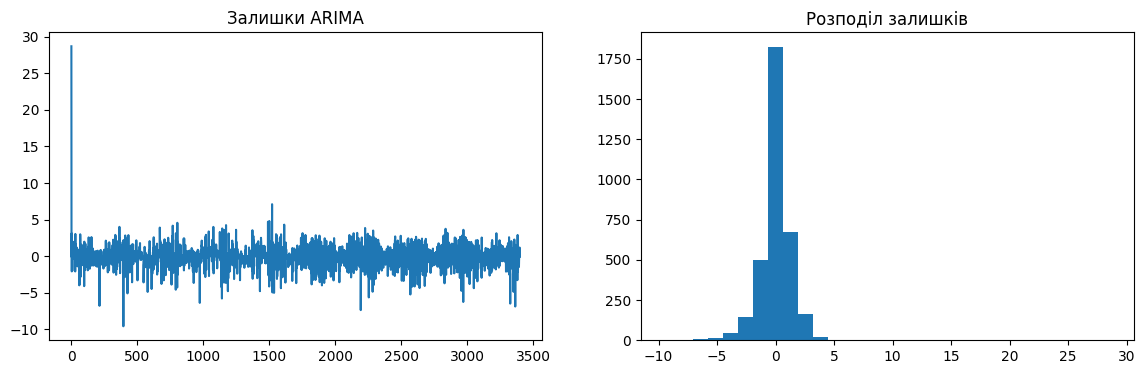

In [85]:
residuals = arima_fit.resid

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(residuals)
ax[0].set_title("Залишки ARIMA")
ax[1].hist(residuals, bins=30)
ax[1].set_title("Розподіл залишків")
plt.show()

In [86]:
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))
arima_mape = mean_absolute_percentage_error(test, arima_forecast)

arima_mae, arima_rmse, arima_mape

(6.2385262016012755,
 np.float64(8.459437993092086),
 np.float64(36.0500735942044))

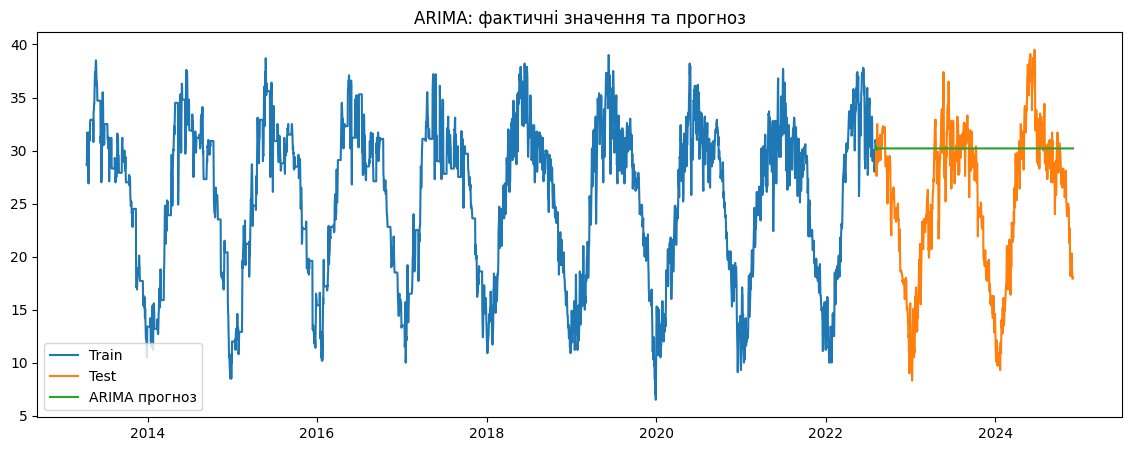

In [87]:
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.plot(test.index, arima_forecast, label="ARIMA прогноз")
plt.legend()
plt.title("ARIMA: фактичні значення та прогноз")
plt.show()

In [88]:
prophet_df = df.reset_index()[["DATE", "temp"]].rename(columns={"DATE": "ds", "temp": "y"})
prophet_train = prophet_df.iloc[:train_size]
prophet_test = prophet_df.iloc[train_size:]

In [89]:
prophet_model = Prophet(daily_seasonality=False, yearly_seasonality=True, weekly_seasonality=True)
prophet_model.fit(prophet_train)

Прогноз

In [90]:
future = prophet_model.make_future_dataframe(periods=len(prophet_test), freq="D")
prophet_forecast_full = prophet_model.predict(future)
prophet_forecast = prophet_test.merge(prophet_forecast_full[["ds", "yhat"]], on="ds", how="left")["yhat"].values

In [91]:
prophet_mae = mean_absolute_error(prophet_test["y"], prophet_forecast)
prophet_rmse = np.sqrt(mean_squared_error(prophet_test["y"], prophet_forecast))
prophet_mape = mean_absolute_percentage_error(prophet_test["y"], prophet_forecast)

prophet_mae, prophet_rmse, prophet_mape

(2.0460176531968286,
 np.float64(2.6146425426476925),
 np.float64(9.260635774112421))

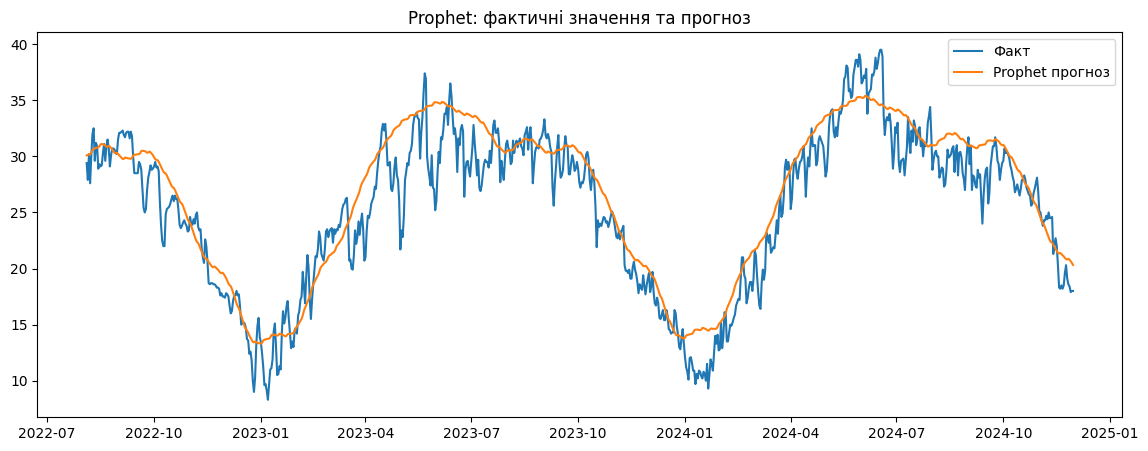

In [92]:
plt.plot(prophet_test["ds"], prophet_test["y"], label="Факт")
plt.plot(prophet_test["ds"], prophet_forecast, label="Prophet прогноз")
plt.legend()
plt.title("Prophet: фактичні значення та прогноз")
plt.show()

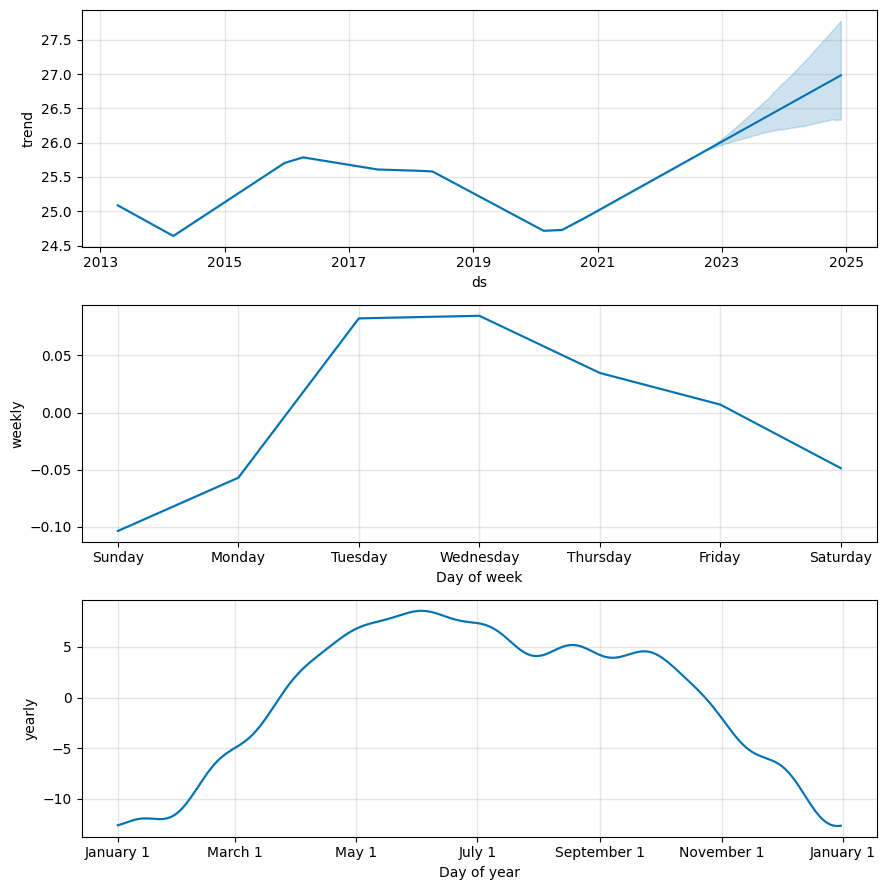

In [93]:
prophet_model.plot_components(prophet_forecast_full)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [94]:
values = df["temp"].values.reshape(-1, 1)

scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(values)

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i - window_size:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

window_size = 30
X, y = create_sequences(scaled_values, window_size)
X = X.reshape(X.shape[0], X.shape[1], 1)

In [95]:
split_index = train_size - window_size

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

X_train.shape, X_test.shape

((3369, 30, 1), (850, 30, 1))

In [96]:
lstm_model = Sequential([
    LSTM(64, activation="tanh", input_shape=(window_size, 1), return_sequences=True),
    LSTM(32, activation="tanh"),
    Dense(1)
])

lstm_model.compile(optimizer="adam", loss="mse")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
history = lstm_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - loss: 0.0215 - val_loss: 0.0048
Epoch 2/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0046 - val_loss: 0.0047
Epoch 3/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0041 - val_loss: 0.0042
Epoch 4/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0039 - val_loss: 0.0038
Epoch 5/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0037 - val_loss: 0.0035
Epoch 6/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0034 - val_loss: 0.0037
Epoch 7/20
41/95 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0034

In [48]:
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

In [49]:
lstm_pred_scaled = lstm_model.predict(X_test)
lstm_forecast = scaler.inverse_transform(lstm_pred_scaled).flatten()
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


In [58]:
all_dates = df.index[window_size:]
lstm_test_dates = all_dates[split_index:]

In [57]:
lstm_mae = mean_absolute_error(y_test_actual, lstm_forecast)
lstm_rmse = np.sqrt(mean_squared_error(y_test_actual, lstm_forecast))
lstm_mape = mean_absolute_percentage_error(y_test_actual, lstm_forecast)

lstm_mae, lstm_rmse, lstm_mape

(1.1397139554613098,
 np.float64(1.4310792789681868),
 np.float64(4.840301238149105))

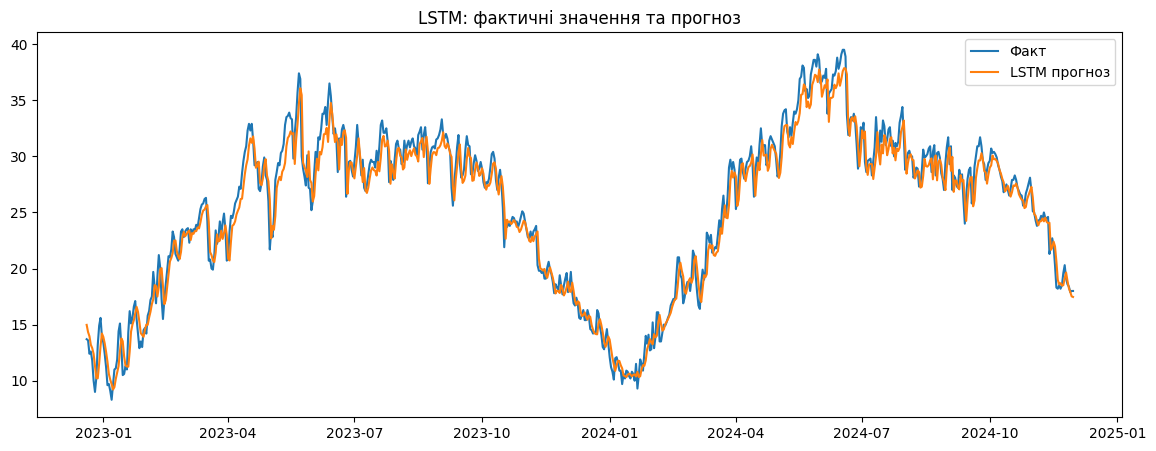

In [56]:
plt.plot(lstm_test_dates, y_test_actual, label="Факт")
plt.plot(lstm_test_dates, lstm_forecast, label="LSTM прогноз")
plt.legend()
plt.title("LSTM: фактичні значення та прогноз")
plt.show()

Порівняння моделей

In [59]:
results = pd.DataFrame({
    "Модель": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [arima_mae, prophet_mae, lstm_mae],
    "RMSE": [arima_rmse, prophet_rmse, lstm_rmse],
    "MAPE": [arima_mape, prophet_mape, lstm_mape]
})
results

,Модель,MAE,RMSE,MAPE
0,ARIMA,11.096322,12.683098,40.123711
1,Prophet,2.004680,2.590197,9.027935
2,LSTM,1.139714,1.431079,4.840301


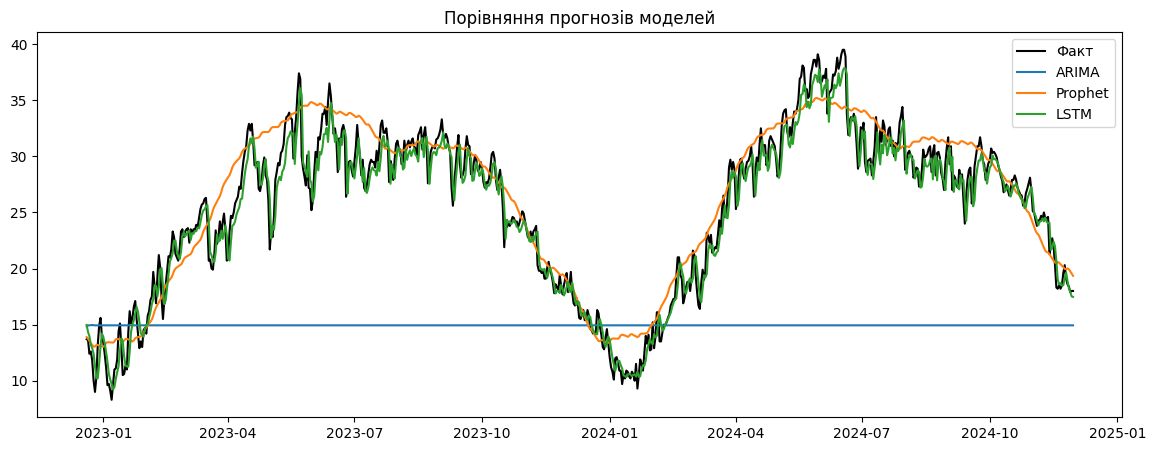

In [60]:
plt.plot(test.index, test, label="Факт", color="black")
plt.plot(test.index, arima_forecast, label="ARIMA")
plt.plot(prophet_test["ds"], prophet_forecast, label="Prophet")
plt.plot(lstm_test_dates, lstm_forecast, label="LSTM")
plt.legend()
plt.title("Порівняння прогнозів моделей")
plt.show()

Висновок

У роботі було виконано аналіз часового ряду середньодобової температури повітря в Делі за 2013-2024 роки. Проведено попередню обробку даних, побудовано графіки зміни температури, ковзного середнього, розподілу та boxplot, а також проаналізовано автокореляційну (ACF) та часткову автокореляційну (PACF) функції, що дало змогу оцінити наявність сезонності та обрати параметри моделі ARIMA.

Для прогнозування температури побудовано три моделі: ARIMA, Prophet та LSTM. За результатами порівняння метрик MAE, RMSE та MAPE найкращу точність прогнозування на тестовій вибірці показала модель **Prophet**, яка краще за інші враховує сезонні коливання температури протягом року. Модель ARIMA показала дещо гіршу точність через обмежену здатність класичних лінійних моделей відтворювати довгострокову сезонність, а LSTM потребує більшого обсягу даних та додаткового підбору гіперпараметрів для покращення результату.